In [63]:
words = open('names.txt').read().splitlines()

# open('names.txt').readlines() gives a python list but each element of the list has a '\n' character at the end. 
# open('names.txt').read().splitlines() gives a python list without the '\n' at the end.

In [2]:
print(type(words))
print(len(words))


<class 'list'>
32033


In [3]:
words[0:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [4]:
min(len(w) for w in words)

2

In [5]:
max(len(w) for w in words)

15

In [20]:
for w in words[:3]:
    chs = ['<S>'] + list(w) + ['<E>']
    for c1, c2 in zip(chs, chs[1:]):
        print(f"{c1}, {c2}")

<S>, e
e, m
m, m
m, a
a, <E>
<S>, o
o, l
l, i
i, v
v, i
i, a
a, <E>
<S>, a
a, v
v, a
a, <E>


In [23]:
b = {}
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1

In [28]:
sorted(b.items(), key=lambda x: x[1], reverse=True ) # Could've skipped reverse=True and modified the lambda to use lambda x: -x[1]

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [29]:
import torch

In [36]:
a = torch.zeros([3,5], dtype=torch.int32)
print(a.size())
a


torch.Size([3, 5])


tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [39]:
a[1,3] += 1
a # Ran this 3 times

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 3, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [41]:
N = torch.zeros((28,28) , dtype=torch.int32)

In [47]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i, s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27

In [49]:
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

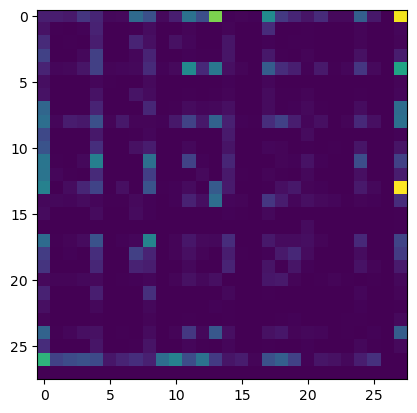

In [51]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.imshow(N)

In [52]:
# We need a better visualization
# so first create an inverse dicitonary
itos = {i:s for s, i in stoi.items()}

In [ ]:
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

### Dummy code from Generator and Sampling Section of Bigram model

In [53]:
# Torch.multinomial
p = torch.tensor([0.6, 0.3, 0.1])

In [56]:
from collections import Counter

In [62]:
freq_map = Counter((torch.multinomial(p, 1000, replacement=True)).tolist())
freq_map

Counter({0: 611, 1: 302, 2: 87})

In [71]:
samples = torch.multinomial(p, 1000, replacement=True)
counts = torch.bincount(samples, minlength=len(p))
counts

tensor([603, 281, 116])

In [72]:
counts / counts.sum()     # tensor([0.611, 0.302, 0.087])

tensor([0.6030, 0.2810, 0.1160])

In [73]:
g = torch.Generator().manual_seed(2147483647)
dummy_p = torch.rand(3, generator=g)
dummy_p = dummy_p /dummy_p .sum()
dummy_p 

tensor([0.6064, 0.3033, 0.0903])

In [74]:
# Now drawing samples from this dummy distribution p. In reality we'll use the distribution 
# created by N[0] but for demonstration purposes we are using a dummy p defined above.